***Download ECOLI_W_API.csv from csv folder and select the exact file and enter the exact name below under the '# load the dataset' section.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ECOLI_W_API.csv to ECOLI_W_API.csv


Logistic Regression F1 Score: 0.6135552913198573
KNN F1 Score: 0.6539923954372624
XGBoost F1 Score: 0.6614785992217899
Linear Regression MSE: 0.2415427616753604
Huber Regression MSE: 0.24150978262126624
Neural Network MSE: 0.22587673426035051


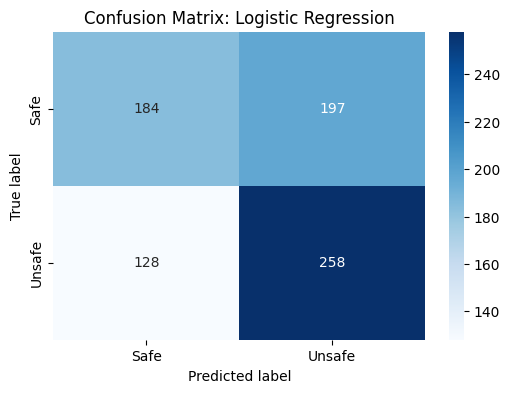

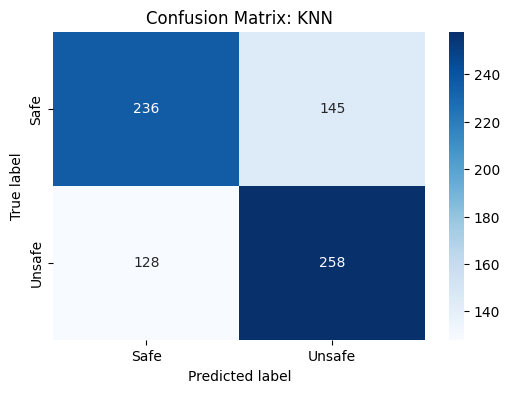

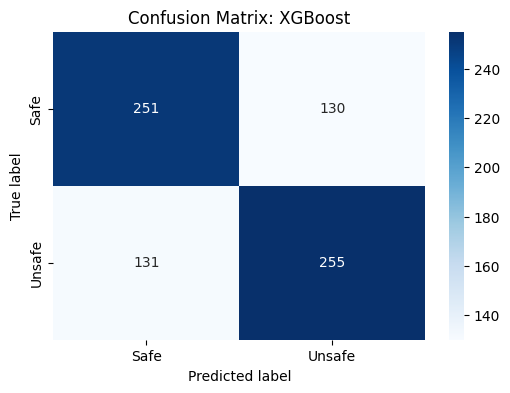

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, mean_squared_error, accuracy_score, confusion_matrix
from xgboost import XGBClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import HuberRegressor

# Load the dataset
df = pd.read_csv("ECOLI_W_API.csv")

# Create binary target variable: 1 if unsafe (>=100), 0 if safe (<100)
df['SAFETY'] = (df['RESULT..MPN.100ML.'] >= 100).astype(int)

# Normalize column names (remove spaces)
df.columns = df.columns.str.replace(' ', '')

# Define initial feature set
features = [
    'TEMPERATURE', 'HUMIDITY', 'PRECIPITATION', 'DEW', 'WINDSPEED', 'WINDGUST',
    'WINDDIR', 'PRESSURE', 'CLOUDCOVER', 'SOLARRADIATION', 'SOLARENERGY', 'UVINDEX'
]

# Fill missing values
df[features] = df[features].fillna(df[features].mean())

# Feature selection based on correlation
correlations = df[features + ['SAFETY']].corr()['SAFETY'].drop('SAFETY').sort_values(ascending=False)
selected_features = correlations[correlations.abs() > 0.05].index.tolist()

# Prepare dataset
X = df[selected_features]
y = df['SAFETY']
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Classification Models - Logistic Regression, KNN, XGBoost
# Logistic Regression
log_model = LogisticRegression()
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)
f1_log = f1_score(y_test, y_pred_log)

# K-Nearest Neighbors
knn_model = KNeighborsClassifier()
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
f1_knn = f1_score(y_test, y_pred_knn)

# XGBoost Classifier
xgb_model = XGBClassifier()
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
f1_xgb = f1_score(y_test, y_pred_xgb)

# Print F1 Scores for Classification Models
print(f"Logistic Regression F1 Score: {f1_log}")
print(f"KNN F1 Score: {f1_knn}")
print(f"XGBoost F1 Score: {f1_xgb}")

# Regression Models - Linear Regression, Huber Regression, Neural Network
# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
mse_lr = mean_squared_error(y_test, y_pred_lr)

# Huber Regression (Robust to outliers)
huber_model = HuberRegressor()
huber_model.fit(X_train, y_train)
y_pred_huber = huber_model.predict(X_test)
mse_huber = mean_squared_error(y_test, y_pred_huber)

# Neural Network Regression
nn_model = MLPRegressor(hidden_layer_sizes=(100,), max_iter=1000)
nn_model.fit(X_train, y_train)
y_pred_nn = nn_model.predict(X_test)
mse_nn = mean_squared_error(y_test, y_pred_nn)

# Print MSE for Regression Models
print(f"Linear Regression MSE: {mse_lr}")
print(f"Huber Regression MSE: {mse_huber}")
print(f"Neural Network MSE: {mse_nn}")

# Optionally: Plotting the confusion matrix for classification
def plot_confusion_matrix(cm, model_name):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Safe', 'Unsafe'], yticklabels=['Safe', 'Unsafe'])
    plt.title(f"Confusion Matrix: {model_name}")
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

# Confusion Matrix for Classification Models
cm_log = confusion_matrix(y_test, y_pred_log)
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plot_confusion_matrix(cm_log, "Logistic Regression")
plot_confusion_matrix(cm_knn, "KNN")
plot_confusion_matrix(cm_xgb, "XGBoost")


***Conclusions: Use XGBoost (has the highest F1 score) if your goal is classifying samples as safe/unsafe — it's doing the best job overall at balancing precision and recall. Use the Neural Network (has the lowest MSE score) if your goal is to predict exact E. coli levels — it has the lowest error.